In [1]:
import torch
import torch.nn as nn
import yfinance as yf
from tqdm import tqdm
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.metrics import f1_score

In [2]:
# hyperparameters
train_test_prop = 0.8
batch_size = 16 # how many independent sequences will we process in parallel?
block_size = 8 # the temporal block size of the model
max_iters = 25
learning_rate = 3e-4
scheduler_step_size = 40
scheduler_gamma = 0.5
device = 'cuda' if torch.cuda.is_available() else 'cpu'
show_stats = True

# model parameters
n_hidden = 128
n_layer = 2
dropout = 0.2
is_lstm = True

torch.manual_seed(1337)

In [3]:
data = yf.download("AMZN")
data.columns = data.columns.droplevel(1)
# data = data["2020-01-01":]


[*********************100%***********************]  1 of 1 completed


In [4]:
data["1D Return"] = data["Close"].pct_change(1)
data["5D Return"] = data["Close"].pct_change(5)
data["20D Return"] = data["Close"].pct_change(20)
data["80D Return"] = data["Close"].pct_change(80)
data["120D Return"] = data["Close"].pct_change(120)
data["160D Return"] = data["Close"].pct_change(160)
data["200D Return"] = data["Close"].pct_change(200)
data["20D EMA"] = data["Close"].ewm(span=20, adjust=False).mean()
data["80D EMA"] = data["Close"].ewm(span=80, adjust=False).mean()
data["120D EMA"] = data["Close"].ewm(span=120, adjust=False).mean()
data["160D EMA"] = data["Close"].ewm(span=160, adjust=False).mean()
data["200D EMA"] = data["Close"].ewm(span=200, adjust=False).mean()
data.dropna(inplace=True)
data

Price,Adj Close,Close,High,Low,Open,Volume,1D Return,5D Return,20D Return,80D Return,120D Return,160D Return,200D Return,20D EMA,80D EMA,120D EMA,160D EMA,200D EMA
Date,,,,,,,,,,,,,,,,,,
1998-03-03,0.298958,0.298958,0.315625,0.297917,0.314583,160320000,-0.059016,0.105970,0.150299,0.205879,0.845659,1.799993,2.053178,0.275335,0.240753,0.223152,0.208131,0.195756
1998-03-04,0.305990,0.305990,0.309375,0.291667,0.300000,146280000,0.023522,0.114803,0.188071,0.255344,0.853317,1.510687,2.539175,0.278254,0.242364,0.224522,0.209347,0.196852
1998-03-05,0.312500,0.312500,0.325781,0.296875,0.298958,240024000,0.021275,0.030928,0.234568,0.340782,0.980192,1.678564,2.658522,0.281516,0.244096,0.225976,0.210628,0.198003
1998-03-06,0.319792,0.319792,0.320833,0.307292,0.315104,117744000,0.023334,-0.003245,0.295360,0.427911,0.734465,1.882619,2.910824,0.285161,0.245965,0.227527,0.211984,0.199215
1998-03-09,0.347917,0.347917,0.357292,0.319792,0.320313,461112000,0.087948,0.095084,0.418257,0.653464,1.249153,2.227041,3.875928,0.291138,0.248482,0.229516,0.213673,0.200695
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-20,224.919998,224.919998,226.210007,218.729996,219.839996,88279200,0.007300,-0.011167,0.133784,0.316862,0.124600,0.207884,0.272028,220.113396,202.257927,196.341309,191.527283,187.144621
2024-12-23,225.059998,225.059998,226.880005,223.899994,225.009995,28070000,0.000622,-0.033787,0.141741,0.307576,0.139025,0.192687,0.283490,220.584501,202.820941,196.815998,191.943838,187.521888
2024-12-24,229.050003,229.050003,229.139999,226.130005,226.940002,15007500,0.017729,-0.009085,0.137007,0.283193,0.145250,0.213446,0.331996,221.390739,203.468572,197.348791,192.404784,187.935104


In [5]:
data.drop(columns=["Close", "Adj Close", "Open", "High", "Low", "Volume"], inplace=True)
data

Price,1D Return,5D Return,20D Return,80D Return,120D Return,160D Return,200D Return,20D EMA,80D EMA,120D EMA,160D EMA,200D EMA
Date,,,,,,,,,,,,
1998-03-03,-0.059016,0.105970,0.150299,0.205879,0.845659,1.799993,2.053178,0.275335,0.240753,0.223152,0.208131,0.195756
1998-03-04,0.023522,0.114803,0.188071,0.255344,0.853317,1.510687,2.539175,0.278254,0.242364,0.224522,0.209347,0.196852
1998-03-05,0.021275,0.030928,0.234568,0.340782,0.980192,1.678564,2.658522,0.281516,0.244096,0.225976,0.210628,0.198003
1998-03-06,0.023334,-0.003245,0.295360,0.427911,0.734465,1.882619,2.910824,0.285161,0.245965,0.227527,0.211984,0.199215
1998-03-09,0.087948,0.095084,0.418257,0.653464,1.249153,2.227041,3.875928,0.291138,0.248482,0.229516,0.213673,0.200695
...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-20,0.007300,-0.011167,0.133784,0.316862,0.124600,0.207884,0.272028,220.113396,202.257927,196.341309,191.527283,187.144621
2024-12-23,0.000622,-0.033787,0.141741,0.307576,0.139025,0.192687,0.283490,220.584501,202.820941,196.815998,191.943838,187.521888
2024-12-24,0.017729,-0.009085,0.137007,0.283193,0.145250,0.213446,0.331996,221.390739,203.468572,197.348791,192.404784,187.935104


In [6]:
split_index = int(data.shape[0] * train_test_prop)
train_x = data.iloc[:split_index]
test_x = data.iloc[split_index:]
train_y = train_x["1D Return"].shift(-1).dropna()
test_y = test_x["1D Return"].shift(-1).dropna()
train_x = train_x.loc[train_y.index]
test_x = test_x.loc[test_y.index]
assert train_x.index.equals(train_y.index)
assert test_x.index.equals(test_y.index)

train_x.shape, train_y.shape, test_x.shape, test_y.shape

((5399, 12), (5399,), (1350, 12), (1350,))

In [7]:
scaler = StandardScaler()
scaler.fit(train_x)
train_x = scaler.transform(train_x)
test_x = scaler.transform(test_x)

In [8]:

class TimeSeriesDataset(Dataset):
    def __init__(self, x, y, block_size):
        self.x = x
        self.y = y
        self.block_size = block_size

    def __len__(self):
        return self.x.shape[0] - self.block_size

    def __getitem__(self, idx):
        return (
            torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
            torch.tensor(self.y[idx], dtype=torch.float32)
        )


In [9]:
train_x = torch.tensor(train_x, dtype=torch.float32).to(device)
train_y = torch.tensor(train_y.values, dtype=torch.float32).unsqueeze(1).to(device)

train_dataset = TimeSeriesDataset(train_x, train_y, block_size)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

test_x = torch.tensor(test_x, dtype=torch.float32).to(device)
test_y = torch.tensor(test_y.values, dtype=torch.float32).unsqueeze(1).to(device)

test_dataset = TimeSeriesDataset(test_x, test_y, block_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [10]:
for i, j in train_loader:
    print(i.shape, j.shape)


C:\Users\luis\AppData\Local\Temp\ipykernel_24640\612109033.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
C:\Users\luis\AppData\Local\Temp\ipykernel_24640\612109033.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.y[idx], dtype=torch.float32)


torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Size([16, 1])
torch.Size([16, 8, 12]) torch.Si

In [11]:
class LSTMModel(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, num_layers: int, output_size: int, dropout: float):
        super(LSTMModel, self).__init__()
        # self.net = nn.Sequential(
        #     nn.Linear(input_size, hidden_size),
        #     nn.ReLU(),
        #     nn.LSTM(hidden_size, hidden_size, num_layers, batch_first=True, dropout=dropout),
        #     nn.Linear(hidden_size, output_size)
        # )
        self.linear = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        if is_lstm:
            self.lstm = nn.LSTM(hidden_size, hidden_size, num_layers, batch_first=True, dropout=dropout)
        self.output = nn.Linear(hidden_size, output_size)
        # self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.LSTM):
            for name, param in module.named_parameters():
                if 'bias' in name:
                    nn.init.constant_(param, 0.0)
                elif 'weight_ih' in name:
                    nn.init.kaiming_normal_(param)
                elif 'weight_hh' in name:
                    nn.init.orthogonal_(param)
    
    def forward(self, idx):
        # idx: (batch_size, block_size, input_size) i.e. B x T x C
        x = self.linear(idx)
        x = self.relu(x)
        if is_lstm:
            x, _ = self.lstm(x)
            x = x[:, -1, :]
        x = self.output(x)
        return x
    

In [12]:

def run_epoch(model, criterion, optimizer, scheduler, dataloader, is_training=False):
    epoch_loss = 0
    if is_training:
        model.train()
    else:
        model.eval()
    for idx, (x, y) in enumerate(dataloader):
        if is_training:
            optimizer.zero_grad()

        batchsize = x.shape[0]


        x = x.to(device)
        y = y.to(device)
                
        out = model(x)
        loss = criterion(out, y)
        

        if is_training:
            loss.backward()
            optimizer.step()
            scheduler.step()

        epoch_loss += (loss.detach().item()) / batchsize
    print(epoch_loss / len(dataloader))
    lr = scheduler.get_last_lr()[0]
    return epoch_loss, lr


In [13]:
# test_model = LSTMModel(input_size=train_x.shape[1], hidden_size=n_hidden, num_layers=n_layer, output_size=1, dropout=dropout).to(device)
# test_criterion = nn.MSELoss()
# test_optimizer = torch.optim.Adam(test_model.parameters(), lr=learning_rate)
# test_scheduler = torch.optim.lr_scheduler.StepLR(test_optimizer, step_size=scheduler_step_size, gamma=scheduler_gamma)

# run_epoch(test_model, test_criterion, test_optimizer, test_scheduler, train_loader, is_training=False)


In [30]:
model = LSTMModel(input_size=train_x.shape[1], hidden_size=n_hidden, num_layers=n_layer, output_size=1, dropout=0.2).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=scheduler_step_size, gamma=scheduler_gamma)
if show_stats:
    train_losses = np.empty(0)
    test_losses = np.empty(0)
for epoch in tqdm(range(max_iters)):

    loss_train, lr_train = run_epoch(model, criterion, optimizer, scheduler, train_loader, is_training=True)
    loss_val, lr_val = run_epoch(model, criterion, optimizer, scheduler, test_loader, is_training=False)
    train_losses = np.append(train_losses, loss_train)
    test_losses = np.append(test_losses, loss_val)

    print('\rEpoch[{}/{}] | loss train:{:.6f}, test:{:.6f} | lr:{:.6f}'
          .format(epoch + 1, max_iters, loss_train, loss_val, lr_train))
    
    


  0%|          | 0/25 [00:00<?, ?it/s]C:\Users\luis\AppData\Local\Temp\ipykernel_24640\612109033.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
C:\Users\luis\AppData\Local\Temp\ipykernel_24640\612109033.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.y[idx], dtype=torch.float32)
  4%|▍         | 1/25 [00:01<00:29,  1.21s/it]

7.915824775999556e-05
3.4472363574955154e-05
Epoch[1/25] | loss train:0.026676, test:0.002896 | lr:0.000001


  8%|▊         | 2/25 [00:02<00:26,  1.14s/it]

7.068500121603367e-05
3.5342303085738474e-05
Epoch[2/25] | loss train:0.023821, test:0.002969 | lr:0.000000


 12%|█▏        | 3/25 [00:03<00:24,  1.10s/it]

...

7.050473610248665e-05
3.5342210228726905e-05
Epoch[4/25] | loss train:0.023760, test:0.002969 | lr:0.000000


 20%|██        | 5/25 [00:05<00:21,  1.08s/it]

7.078611391437043e-05
3.5342210228726905e-05
Epoch[5/25] | loss train:0.023855, test:0.002969 | lr:0.000000


 20%|██        | 5/25 [00:05<00:23,  1.16s/it]


KeyboardInterrupt: 

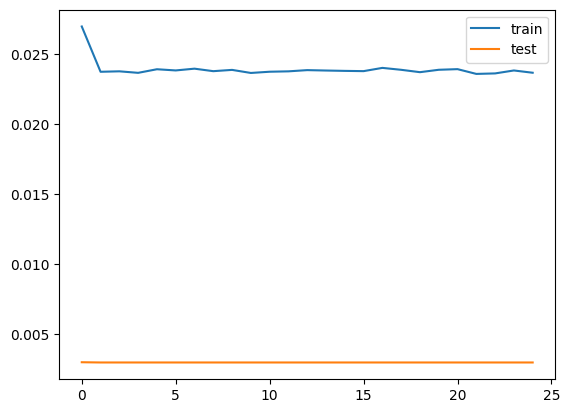

In [15]:
plt.plot(train_losses, label='train')
plt.plot(test_losses, label='test')
plt.legend()
plt.show()

In [16]:
train_losses, test_losses

(array([0.02698133, 0.02374719, 0.02377994, 0.02367167, 0.02392813,
        0.02384317, 0.02396938, 0.02379064, 0.02388218, 0.02366327,
        0.02375102, 0.02377852, 0.02386555, 0.02383663, 0.0238116 ,
        0.02379309, 0.02402508, 0.02388834, 0.02371877, 0.02389003,
        0.02393532, 0.02359511, 0.02363021, 0.02384068, 0.02367846]),
 array([0.00301209, 0.00299516, 0.00299513, 0.00299513, 0.00299513,
        0.00299513, 0.00299513, 0.00299513, 0.00299513, 0.00299513,
        0.00299513, 0.00299513, 0.00299513, 0.00299513, 0.00299513,
        0.00299513, 0.00299513, 0.00299513, 0.00299513, 0.00299513,
        0.00299513, 0.00299513, 0.00299513, 0.00299513, 0.00299513]))

In [17]:


model.eval()

predicted_train = np.array([])

for idx, (x, y) in enumerate(train_loader):
    # print(scaler.inverse_transform(x.cpu()), y) TODO: CHECK WHAT THIS IS PREDICTING!
    x = x.to(device)
    out = model(x)
    out = out.cpu().detach().numpy()
    predicted_train = np.concatenate((predicted_train, out.squeeze(-1)))

predicted_val = np.array([])

for idx, (x, y) in enumerate(test_loader):
    x = x.to(device)
    out = model(x)
    out = out.cpu().detach().numpy()
    predicted_val = np.concatenate((predicted_val, out.squeeze(-1)))



C:\Users\luis\AppData\Local\Temp\ipykernel_24640\612109033.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
C:\Users\luis\AppData\Local\Temp\ipykernel_24640\612109033.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(self.y[idx], dtype=torch.float32)


In [18]:
predicted_train.mean(), predicted_train.std(), predicted_val.mean(), predicted_val.std()

(np.float64(0.00136595557006209),
 np.float64(0.012789958309565303),
 np.float64(-0.009805532944029206),
 np.float64(0.006530711099028481))

In [19]:
to_plot_data_y_train_pred = np.zeros(len(data))
to_plot_data_y_val_pred = np.zeros(len(data))

to_plot_data_y_train_pred[:split_index-block_size-1] = predicted_train
to_plot_data_y_val_pred[split_index+block_size+1:] = predicted_val

to_plot_data_y_train_pred = np.where(to_plot_data_y_train_pred == 0, None, to_plot_data_y_train_pred)
to_plot_data_y_val_pred = np.where(to_plot_data_y_val_pred == 0, None, to_plot_data_y_val_pred)


In [27]:
# backtesting!

y_train = train_loader.dataset.y.detach().cpu().numpy()[block_size:]

train_mse = sum((y_train.squeeze() - predicted_train)**2) / predicted_train.size

y_val = test_loader.dataset.y.detach().cpu().numpy()[block_size:]
val_mse = sum((y_val.squeeze() - predicted_val)**2) / predicted_val.size

# predicted_train > 0, data["1D Return"].iloc[:split_index-1] > 0
# f1 score
# IMPORTANT!!! TRUE AND PREDICTED ARE BACKWARDS. PLUS 1 TO SHIFT THE PREDICTION TO THE NEXT DAY???
f1_train = f1_score(y_train > 0, predicted_train > 0)
f1_val = f1_score(y_val > 0, predicted_val > 0)


In [28]:
# baseline!

baseline_mse = sum((data["1D Return"].iloc[:split_index-1].shift(-1) - data["1D Return"].iloc[:split_index-1]).dropna()) / (split_index-1)
baseline_f1 = f1_score(data["1D Return"].iloc[:split_index-1].shift(-1) > 0, data["1D Return"].iloc[:split_index-1] > 0)

train_mse, val_mse, f1_train, f1_val, baseline_mse, baseline_f1

(np.float64(0.0015296226016299032),
 np.float64(0.0006423318819255896),
 0.5215189873417722,
 0.1198501872659176,
 4.699269474537871e-06,
 0.5029133284777859)


Model: epochs 25, dropout 0.2, is_lstm True, hidden_size 128, num_layers 2, lr 0.0003, scheduler_step_size 40, scheduler_gamma 0.5
Performance: train_mse 0.0015296226016299032, val_mse 0.0006423318819255896, f1_train 0.5215189873417722, f1_val 0.1198501872659176
Baseline: mse 4.699269474537871e-06, f1 0.5029133284777859
Comp to baseline: train_mse 32450.22%, val_mse 13568.76%, f1_train 3.7%, f1_val -76.17%



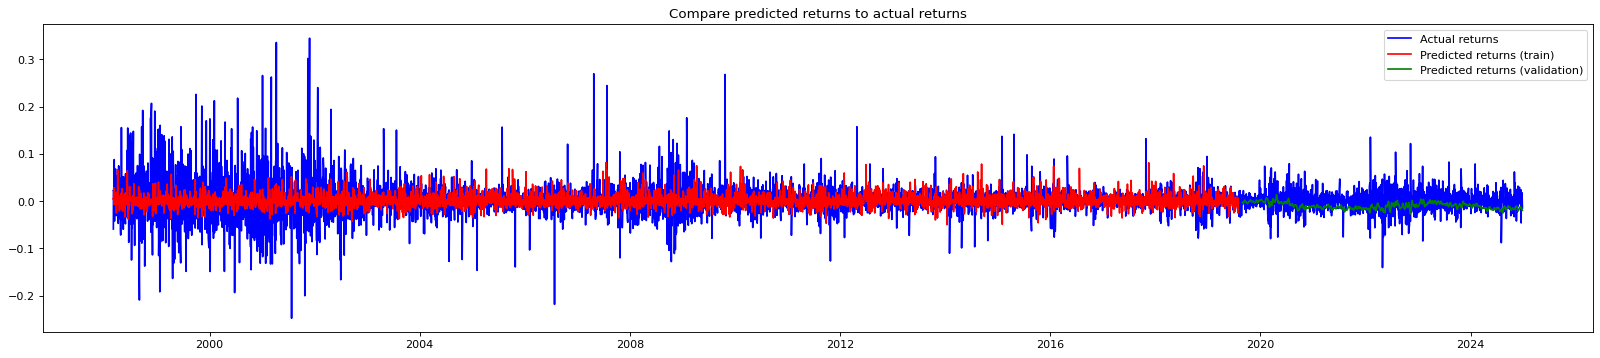

In [29]:
print(f"""
Model: epochs {max_iters}, dropout {dropout}, is_lstm {is_lstm},{f' hidden_size {n_hidden}, num_layers {n_layer},' if is_lstm else ''} lr {learning_rate}, scheduler_step_size {scheduler_step_size}, scheduler_gamma {scheduler_gamma}
Performance: train_mse {train_mse}, val_mse {val_mse}, f1_train {f1_train}, f1_val {f1_val}
Baseline: mse {baseline_mse}, f1 {baseline_f1}
Comp to baseline: train_mse {round((((train_mse - baseline_mse) / baseline_mse) * 100), 2)}%, val_mse {round((((val_mse - baseline_mse) / baseline_mse) * 100), 2)}%, f1_train {round((((f1_train - baseline_f1) / baseline_f1)*100), 2)}%, f1_val {round((((f1_val - baseline_f1) / baseline_f1)*100), 2)}%
""")




dates = data.index


fig = plt.figure(figsize=(25, 5), dpi=80)
fig.patch.set_facecolor((1.0, 1.0, 1.0))
plt.plot(dates, data["1D Return"], label="Actual returns", color="blue")
plt.plot(dates, to_plot_data_y_train_pred, label="Predicted returns (train)", color="red")
plt.plot(dates, to_plot_data_y_val_pred, label="Predicted returns (validation)", color="green")
plt.title("Compare predicted returns to actual returns")
# plt.grid(b=None, which='major', axis='y', linestyle='--')
plt.legend()
plt.show()

In [23]:
model.parameters

<bound method Module.parameters of LSTMModel(
  (linear): Linear(in_features=12, out_features=128, bias=True)
  (relu): ReLU()
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.2)
  (output): Linear(in_features=128, out_features=1, bias=True)
)>